In [4]:
import os
import shutil
import subprocess
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch

print("=" * 80)
print("[NOTEBOOK 3] RESNET VS. U-NET CROSS-TRAINING & ENSEMBLE BENCHMARK")
print("=" * 80)

# Check and reset GPU memory
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    free_gb = torch.cuda.mem_get_info()[0] / (1024**3)
    total_gb = torch.cuda.mem_get_info()[1] / (1024**3)
    print(f"✓ GPU: {torch.cuda.get_device_name(0)} | Free VRAM: {free_gb:.2f} GB / {total_gb:.2f} GB")
    if free_gb < 10.0:
        print("⚠️ Warning: Low VRAM detected. Run 'Runtime' -> 'Restart session' if needed.")

# Setup Kaggle credentials if uploaded
if Path("/content/kaggle.json").exists():
    Path("/root/.kaggle").mkdir(parents=True, exist_ok=True)
    shutil.copy("/content/kaggle.json", "/root/.kaggle/kaggle.json")
    os.chmod("/root/.kaggle/kaggle.json", 0o600)

KAGGLE_SLUG = "cjinny/mrnet-v1"
download_dir = Path("/content/mrnet_download")
raw_dir = Path("/content/mrnet_raw")
target_mrnet_dir = raw_dir / "MRNet-v1.0"

if not (target_mrnet_dir / "train-acl.csv").exists():
    if download_dir.exists():
        shutil.rmtree(download_dir)
    download_dir.mkdir(parents=True, exist_ok=True)

    print(f"⬇️ Downloading dataset '{KAGGLE_SLUG}'...")
    subprocess.run([
        "kaggle", "datasets", "download",
        "-d", KAGGLE_SLUG,
        "-p", str(download_dir),
        "--unzip"
    ], check=True)

    found_acl = list(download_dir.rglob("train-acl.csv"))
    if not found_acl:
        raise FileNotFoundError("✗ Could not find train-acl.csv in downloaded files.")

    source_root = found_acl[0].parent
    if target_mrnet_dir.exists():
        shutil.rmtree(target_mrnet_dir)
    target_mrnet_dir.mkdir(parents=True, exist_ok=True)

    for item in source_root.iterdir():
        dest = target_mrnet_dir / item.name
        if item == target_mrnet_dir:
            continue
        if dest.exists():
            if dest.is_dir():
                shutil.rmtree(dest)
            else:
                dest.unlink()
        shutil.move(str(item), str(dest))
    print(f"✓ Dataset extracted and structured into {target_mrnet_dir}")
else:
    print(f"✓ Verified existing dataset at {target_mrnet_dir}")

[NOTEBOOK 3] RESNET VS. U-NET CROSS-TRAINING & ENSEMBLE BENCHMARK
✓ GPU: Tesla T4 | Free VRAM: 14.46 GB / 14.56 GB
⬇️ Downloading dataset 'cjinny/mrnet-v1'...
✓ Dataset extracted and structured into /content/mrnet_raw/MRNet-v1.0


In [5]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from typing import Tuple

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DATA_ROOT = Path("/content/mrnet_raw/MRNet-v1.0")

def build_master_dataframe(split: str) -> pd.DataFrame:
    tasks = ["abnormal", "acl", "meniscus"]
    dfs = []
    for task in tasks:
        csv_path = DATA_ROOT / f"{split}-{task}.csv"
        df_task = pd.read_csv(csv_path, header=None, names=["case_id", task], dtype={0: int, 1: int})
        df_task["case_id"] = df_task["case_id"].apply(lambda x: f"{x:04d}")
        dfs.append(df_task)

    master_df = dfs[0]
    for df in dfs[1:]:
        master_df = master_df.merge(df, on="case_id", how="inner")

    master_df["sagittal_path"] = master_df["case_id"].apply(
        lambda cid: str(DATA_ROOT / split / "sagittal" / f"{cid}.npy")
    )
    valid_mask = master_df["sagittal_path"].apply(os.path.exists)
    return master_df[valid_mask].reset_index(drop=True)

train_df = build_master_dataframe("train")
valid_df = build_master_dataframe("valid")

# Split by MRI CASE into two equal, disjoint 50/50 partitions
train_part_a, train_part_b = train_test_split(
    train_df,
    test_size=0.5,
    random_state=SEED,
    stratify=train_df["abnormal"]
)

train_part_a = train_part_a.reset_index(drop=True)
train_part_b = train_part_b.reset_index(drop=True)

print(f"✓ Full Train Cohort : {len(train_df)} cases")
print(f"  ├── Part A Cohort : {len(train_part_a)} cases")
print(f"  └── Part B Cohort : {len(train_part_b)} cases")
print(f"✓ Test/Valid Cohort : {len(valid_df)} cases\n")

class FastMRNetDataset(Dataset):
    def __init__(self, df: pd.DataFrame, is_train: bool = True):
        self.df = df.reset_index(drop=True)
        self.is_train = is_train
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor, str]:
        row = self.df.iloc[idx]
        volume = np.load(row["sagittal_path"])
        tensor = torch.from_numpy(volume).float() / 255.0
        tensor = tensor.unsqueeze(1).repeat(1, 3, 1, 1)

        if self.is_train:
            if torch.rand(1).item() > 0.5:
                tensor = torch.flip(tensor, dims=[-1])
            if torch.rand(1).item() > 0.5:
                angle = float(torch.empty(1).uniform_(-10, 10).item())
                tensor = TF.rotate(tensor, angle)

        tensor = (tensor - self.mean) / self.std
        labels = torch.tensor([row["abnormal"], row["acl"], row["meniscus"]], dtype=torch.float32)
        return tensor, labels, row["case_id"]

# DataLoaders
loader_part_a = DataLoader(FastMRNetDataset(train_part_a, is_train=True), batch_size=1, shuffle=True, num_workers=2, pin_memory=True)
loader_part_b = DataLoader(FastMRNetDataset(train_part_b, is_train=True), batch_size=1, shuffle=True, num_workers=2, pin_memory=True)
val_loader    = DataLoader(FastMRNetDataset(valid_df, is_train=False), batch_size=1, shuffle=False, num_workers=2, pin_memory=True)

# Balance weights
pos_counts = train_df[["abnormal", "acl", "meniscus"]].sum().values
neg_counts = len(train_df) - pos_counts
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pos_weights = torch.clamp(torch.tensor(neg_counts / pos_counts, dtype=torch.float32), min=1.0).to(device)
criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weights)
print(f"✓ Loss configured with clamped clinical weights: {pos_weights.cpu().numpy().round(2).tolist()}")

✓ Full Train Cohort : 1130 cases
  ├── Part A Cohort : 565 cases
  └── Part B Cohort : 565 cases
✓ Test/Valid Cohort : 120 cases

✓ Loss configured with clamped clinical weights: [1.0, 4.429999828338623, 1.850000023841858]


In [6]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights

# -------------------------------------------------------------
# 1. RESNET-18 ARCHITECTURE
# -------------------------------------------------------------
class ResNetMRNetModel(nn.Module):
    def __init__(self, num_classes: int = 3, dropout_rate: float = 0.5):
        super().__init__()
        weights = ResNet18_Weights.DEFAULT
        base = resnet18(weights=weights)
        self.feature_extractor = nn.Sequential(*list(base.children())[:-1])
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(512, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.dim() == 5:
            x = x.squeeze(0)
        feats = self.feature_extractor(x)  # (S, 512, 1, 1)
        feats = feats.view(feats.size(0), -1)
        patient_rep, _ = torch.max(feats, dim=0, keepdim=True)
        return self.classifier(patient_rep)

# -------------------------------------------------------------
# 2. ULTRA-EFFICIENT U-NET ARCHITECTURE (LayerNorm + Chunking)
# -------------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.net(x)

class Down(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.net = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_ch, out_ch))
    def forward(self, x):
        return self.net(x)

class Up(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.conv = DoubleConv(out_ch * 2, out_ch)

    def forward(self, x1, x2):
        x1 = self.up(x1)
        diff_y = x2.size(2) - x1.size(2)
        diff_x = x2.size(3) - x1.size(3)
        if diff_x > 0 or diff_y > 0:
            x1 = F.pad(x1, [diff_x // 2, diff_x - diff_x // 2,
                           diff_y // 2, diff_y - diff_y // 2])
        return self.conv(torch.cat([x2, x1], dim=1))

class UNetFeatureExtractor(nn.Module):
    def __init__(self, in_channels: int = 3, base_channels: int = 16, feature_dim: int = 512):
        super().__init__()
        self.inc = DoubleConv(in_channels, base_channels)          # 3 -> 16
        self.down1 = Down(base_channels, base_channels * 2)       # 16 -> 32
        self.down2 = Down(base_channels * 2, base_channels * 4)   # 32 -> 64
        self.down3 = Down(base_channels * 4, base_channels * 8)   # 64 -> 128
        self.down4 = Down(base_channels * 8, base_channels * 16)  # 128 -> 256

        self.up1 = Up(base_channels * 16, base_channels * 8)      # 256 -> 128
        self.up2 = Up(base_channels * 8, base_channels * 4)       # 128 -> 64
        self.up3 = Up(base_channels * 4, base_channels * 2)       # 64 -> 32
        self.up4 = Up(base_channels * 2, base_channels)           # 32 -> 16

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        fused_dim = (base_channels * 16) + base_channels           # 256 + 16 = 272
        self.fc_proj = nn.Sequential(
            nn.Linear(fused_dim, feature_dim),
            nn.LayerNorm(feature_dim),
            nn.ReLU(inplace=True)
        )

    def _forward_chunk(self, x_chunk):
        x1 = self.inc(x_chunk)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        d1 = self.up1(x5, x4)
        d2 = self.up2(d1, x3)
        d3 = self.up3(d2, x2)
        d4 = self.up4(d3, x1)

        p_bot = self.pool(x5).flatten(1)
        p_dec = self.pool(d4).flatten(1)
        return self.fc_proj(torch.cat([p_bot, p_dec], dim=1))

    def forward(self, x, chunk_size: int = 4):
        num_slices = x.size(0)
        if num_slices <= chunk_size:
            return self._forward_chunk(x)
        feats, i = [], 0
        while i < num_slices:
            rem = num_slices - i
            cur = rem if rem == chunk_size + 1 else min(chunk_size, rem)
            feats.append(self._forward_chunk(x[i : i + cur]))
            i += cur
        return torch.cat(feats, dim=0)

class UNetMRNetModel(nn.Module):
    def __init__(self, num_classes: int = 3, dropout_rate: float = 0.5):
        super().__init__()
        self.feature_extractor = UNetFeatureExtractor(in_channels=3, base_channels=16, feature_dim=512)
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(512, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.dim() == 5:
            x = x.squeeze(0)
        slice_feats = self.feature_extractor(x)
        patient_rep, _ = torch.max(slice_feats, dim=0, keepdim=True)
        return self.classifier(patient_rep)

print("✓ Both ResNetMRNetModel and UNetMRNetModel architectures ready.")

✓ Both ResNetMRNetModel and UNetMRNetModel architectures ready.


In [7]:
import time
from sklearn.metrics import roc_auc_score

def evaluate_model(model: nn.Module, loader: DataLoader, device: torch.device) -> Tuple[np.ndarray, np.ndarray, float]:
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for volume, labels, _ in loader:
            volume = volume.squeeze(0).to(device)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits = model(volume)
                probs = torch.sigmoid(logits)
            all_preds.append(probs.cpu().numpy()[0])
            all_targets.append(labels.numpy()[0])

    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)

    task_aucs = []
    for i in range(3):
        try:
            task_aucs.append(roc_auc_score(all_targets[:, i], all_preds[:, i]))
        except ValueError:
            task_aucs.append(0.50)
    mean_auc = float(np.mean(task_aucs))
    return all_preds, all_targets, mean_auc


def train_single_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    save_path: str,
    epochs: int = 8,
    lr_backbone: float = 1e-4,
    lr_head: float = 5e-4
) -> nn.Module:
    model.to(device)
    optimizer = torch.optim.AdamW([
        {"params": model.feature_extractor.parameters(), "lr": lr_backbone},
        {"params": model.classifier.parameters(), "lr": lr_head}
    ], weight_decay=1e-3)

    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))
    best_auc = 0.0

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0

        for volume, labels, _ in train_loader:
            volume = volume.squeeze(0).to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits = model(volume)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()

        # Validation at epoch end
        _, _, val_auc = evaluate_model(model, val_loader, device)
        avg_loss = running_loss / len(train_loader)
        print(f"  Epoch {epoch:02d}/{epochs:02d} | Train Loss: {avg_loss:.4f} | Val Mean ROC-AUC: {val_auc:.4f}")

        if val_auc > best_auc:
            best_auc = val_auc
            torch.save(model.state_dict(), save_path)

    # Reload best saved checkpoint
    model.load_state_dict(torch.load(save_path))
    print(f"  🌟 Best Model Loaded with Peak Val AUC: {best_auc:.4f}\n")
    return model

In [8]:
EPOCHS_PER_MODEL = 8

print("=" * 80)
print("🚀 RUNNING EXPERIMENT 1")
print("=" * 80)

# 1. Model 1: ResNet on Part A
print("\n[Exp 1 - Model 1/2] Training ResNet-18 on Part A...")
model_resnet_a = ResNetMRNetModel(num_classes=3)
model_resnet_a = train_single_model(
    model_resnet_a, loader_part_a, val_loader, criterion, device,
    save_path="/content/resnet_part_a.pth", epochs=EPOCHS_PER_MODEL
)
gc.collect(); torch.cuda.empty_cache()

# 2. Model 2: U-Net on Part B
print("\n[Exp 1 - Model 2/2] Training U-Net on Part B...")
model_unet_b = UNetMRNetModel(num_classes=3)
model_unet_b = train_single_model(
    model_unet_b, loader_part_b, val_loader, criterion, device,
    save_path="/content/unet_part_b.pth", epochs=EPOCHS_PER_MODEL
)
gc.collect(); torch.cuda.empty_cache()

print("=" * 80)
print("🚀 RUNNING EXPERIMENT 2")
print("=" * 80)

# 3. Model 3: U-Net on Part A
print("\n[Exp 2 - Model 1/2] Training U-Net on Part A...")
model_unet_a = UNetMRNetModel(num_classes=3)
model_unet_a = train_single_model(
    model_unet_a, loader_part_a, val_loader, criterion, device,
    save_path="/content/unet_part_a.pth", epochs=EPOCHS_PER_MODEL
)
gc.collect(); torch.cuda.empty_cache()

# 4. Model 4: ResNet on Part B
print("\n[Exp 2 - Model 2/2] Training ResNet-18 on Part B...")
model_resnet_b = ResNetMRNetModel(num_classes=3)
model_resnet_b = train_single_model(
    model_resnet_b, loader_part_b, val_loader, criterion, device,
    save_path="/content/resnet_part_b.pth", epochs=EPOCHS_PER_MODEL
)
gc.collect(); torch.cuda.empty_cache()

print("✓ All 4 models successfully trained and check-pointed!")

🚀 RUNNING EXPERIMENT 1

[Exp 1 - Model 1/2] Training ResNet-18 on Part A...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s]


  Epoch 01/08 | Train Loss: 1.7496 | Val Mean ROC-AUC: 0.5015
  Epoch 02/08 | Train Loss: 1.5247 | Val Mean ROC-AUC: 0.4531
  Epoch 03/08 | Train Loss: 1.4689 | Val Mean ROC-AUC: 0.4956
  Epoch 04/08 | Train Loss: 1.3574 | Val Mean ROC-AUC: 0.5131
  Epoch 05/08 | Train Loss: 1.3175 | Val Mean ROC-AUC: 0.5085
  Epoch 06/08 | Train Loss: 1.2964 | Val Mean ROC-AUC: 0.4537
  Epoch 07/08 | Train Loss: 1.3367 | Val Mean ROC-AUC: 0.5052
  Epoch 08/08 | Train Loss: 1.2331 | Val Mean ROC-AUC: 0.4788
  🌟 Best Model Loaded with Peak Val AUC: 0.5131


[Exp 1 - Model 2/2] Training U-Net on Part B...
  Epoch 01/08 | Train Loss: 1.3529 | Val Mean ROC-AUC: 0.5774
  Epoch 02/08 | Train Loss: 1.3549 | Val Mean ROC-AUC: 0.5516
  Epoch 03/08 | Train Loss: 1.3935 | Val Mean ROC-AUC: 0.5551
  Epoch 04/08 | Train Loss: 1.3277 | Val Mean ROC-AUC: 0.5165
  Epoch 05/08 | Train Loss: 1.3200 | Val Mean ROC-AUC: 0.4832
  Epoch 06/08 | Train Loss: 1.2948 | Val Mean ROC-AUC: 0.4617
  Epoch 07/08 | Train Loss: 1.3216

📊 EVALUATION, ENSEMBLING & STATISTICAL COMPARISON

🔍 Running inference on test/validation cohort...

📋 COMPREHENSIVE PERFORMANCE COMPARISON TABLE
                                    Accuracy (%)  Precision (%)  Recall (%)  F1-Score  Mean ROC-AUC  Abnormal AUC  ACL AUC  Meniscus AUC
Model / Ensemble                                                                                                                        
ResNet (Part A)                           58.333         27.426      22.807     0.249         0.513         0.612    0.379         0.548
U-Net (Part B)                            63.611         26.389      33.333     0.295         0.577         0.549    0.614         0.569
U-Net (Part A)                            63.611         26.389      33.333     0.295         0.526         0.569    0.453         0.555
ResNet (Part B)                           64.444         76.049      45.708     0.466         0.656         0.522    0.926         0.520
Ensemble Exp 1 (ResNet_A + UNet_

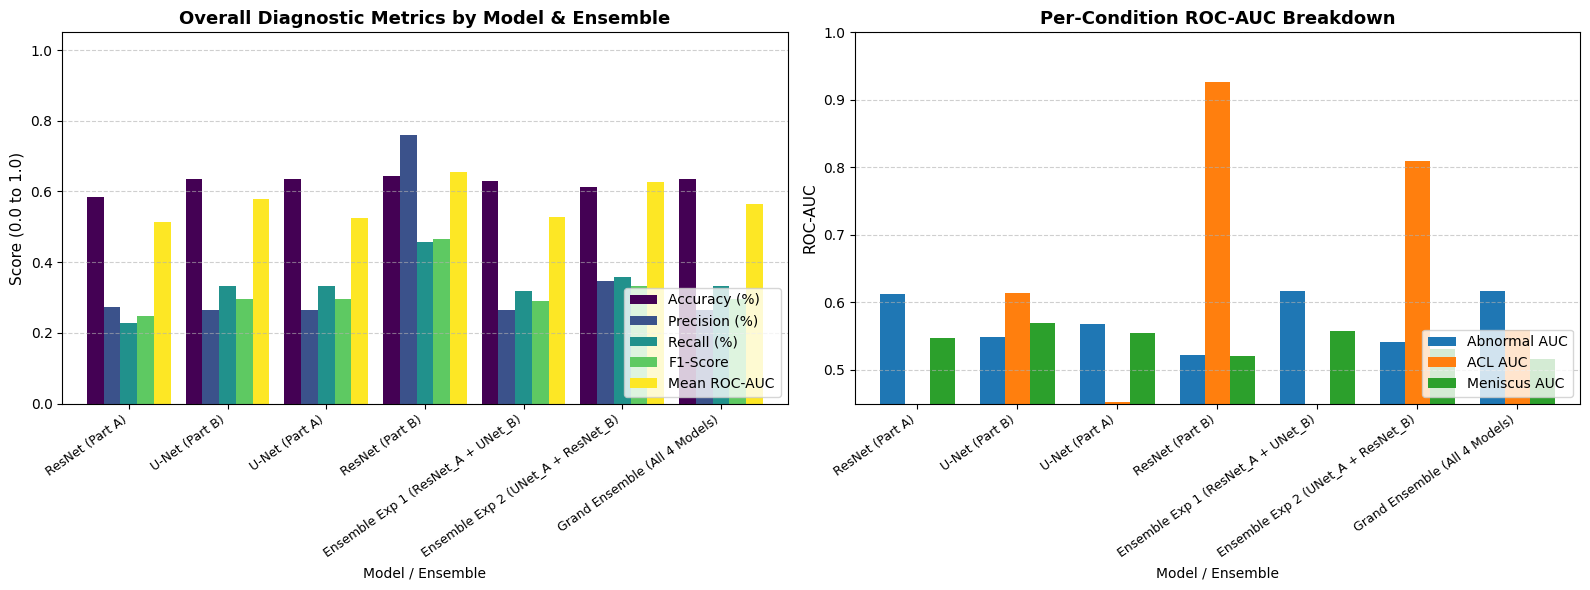

In [11]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

print("=" * 80)
print("📊 EVALUATION, ENSEMBLING & STATISTICAL COMPARISON")
print("=" * 80)

# 1. Ensure models are loaded (auto-loads from disk if kernel was restarted)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def get_or_load_model(model_var_name, model_class, ckpt_path):
    if model_var_name in globals() and globals()[model_var_name] is not None:
        model = globals()[model_var_name]
    else:
        print(f"🔄 Reloading {model_var_name} from {ckpt_path}...")
        model = model_class(num_classes=3).to(device)
        model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()
    return model

m_res_a = get_or_load_model("model_resnet_a", ResNetMRNetModel, "/content/resnet_part_a.pth")
m_une_b = get_or_load_model("model_unet_b", UNetMRNetModel, "/content/unet_part_b.pth")
m_une_a = get_or_load_model("model_unet_a", UNetMRNetModel, "/content/unet_part_a.pth")
m_res_b = get_or_load_model("model_resnet_b", ResNetMRNetModel, "/content/resnet_part_b.pth")

# 2. Extract Validation Predictions
print("\n🔍 Running inference on test/validation cohort...")
probs_res_a, y_true, _ = evaluate_model(m_res_a, val_loader, device)
probs_une_b, _, _      = evaluate_model(m_une_b, val_loader, device)
probs_une_a, _, _      = evaluate_model(m_une_a, val_loader, device)
probs_res_b, _, _      = evaluate_model(m_res_b, val_loader, device)

# 3. Create Ensembles via Probability Averaging
probs_ens_exp1  = (probs_res_a + probs_une_b) / 2.0
probs_ens_exp2  = (probs_une_a + probs_res_b) / 2.0
probs_ens_grand = (probs_res_a + probs_une_b + probs_une_a + probs_res_b) / 4.0

predictions_dict = {
    "ResNet (Part A)": probs_res_a,
    "U-Net (Part B)": probs_une_b,
    "U-Net (Part A)": probs_une_a,
    "ResNet (Part B)": probs_res_b,
    "Ensemble Exp 1 (ResNet_A + UNet_B)": probs_ens_exp1,
    "Ensemble Exp 2 (UNet_A + ResNet_B)": probs_ens_exp2,
    "Grand Ensemble (All 4 Models)": probs_ens_grand
}

# 4. Compute Comprehensive Metrics
def compute_all_metrics(y_true: np.ndarray, y_prob: np.ndarray) -> dict:
    y_pred = (y_prob >= 0.5).astype(int)
    accs, precs, recs, f1s, aucs = [], [], [], [], []

    for i in range(3):
        accs.append(accuracy_score(y_true[:, i], y_pred[:, i]))
        precs.append(precision_score(y_true[:, i], y_pred[:, i], zero_division=0))
        recs.append(recall_score(y_true[:, i], y_pred[:, i], zero_division=0))
        f1s.append(f1_score(y_true[:, i], y_pred[:, i], zero_division=0))
        try:
            aucs.append(roc_auc_score(y_true[:, i], y_prob[:, i]))
        except ValueError:
            aucs.append(0.50)

    return {
        "Accuracy (%)": np.mean(accs) * 100,
        "Precision (%)": np.mean(precs) * 100,
        "Recall (%)": np.mean(recs) * 100,
        "F1-Score": np.mean(f1s),
        "Mean ROC-AUC": np.mean(aucs),
        "Abnormal AUC": aucs[0],
        "ACL AUC": aucs[1],
        "Meniscus AUC": aucs[2]
    }

summary_records = []
for name, probs in predictions_dict.items():
    metrics = compute_all_metrics(y_true, probs)
    metrics["Model / Ensemble"] = name
    summary_records.append(metrics)

# Define and display summary_df
summary_df = pd.DataFrame(summary_records).set_index("Model / Ensemble")
print("\n" + "=" * 80)
print("📋 COMPREHENSIVE PERFORMANCE COMPARISON TABLE")
print("=" * 80)
print(summary_df.round(3).to_string())

# 5. Plot Comparison Bar Charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot A: Overall Diagnostics
scaled_df = summary_df.copy()
scaled_df["Accuracy (%)"] /= 100.0
scaled_df["Precision (%)"] /= 100.0
scaled_df["Recall (%)"] /= 100.0

scaled_df[["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score", "Mean ROC-AUC"]].plot(
    kind="bar", ax=axes[0], colormap="viridis", width=0.85
)
axes[0].set_title("Overall Diagnostic Metrics by Model & Ensemble", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Score (0.0 to 1.0)", fontsize=11)
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xticklabels(summary_df.index, rotation=35, ha="right", fontsize=9)
axes[0].grid(axis="y", linestyle="--", alpha=0.6)
axes[0].legend(loc="lower right", frameon=True)

# Plot B: Condition-Wise ROC-AUC Breakdown
summary_df[["Abnormal AUC", "ACL AUC", "Meniscus AUC"]].plot(
    kind="bar", ax=axes[1], color=["#1f77b4", "#ff7f0e", "#2ca02c"], width=0.75
)
axes[1].set_title("Per-Condition ROC-AUC Breakdown", fontsize=13, fontweight='bold')
axes[1].set_ylabel("ROC-AUC", fontsize=11)
axes[1].set_ylim([0.45, 1.0])
axes[1].set_xticklabels(summary_df.index, rotation=35, ha="right", fontsize=9)
axes[1].grid(axis="y", linestyle="--", alpha=0.6)
axes[1].legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

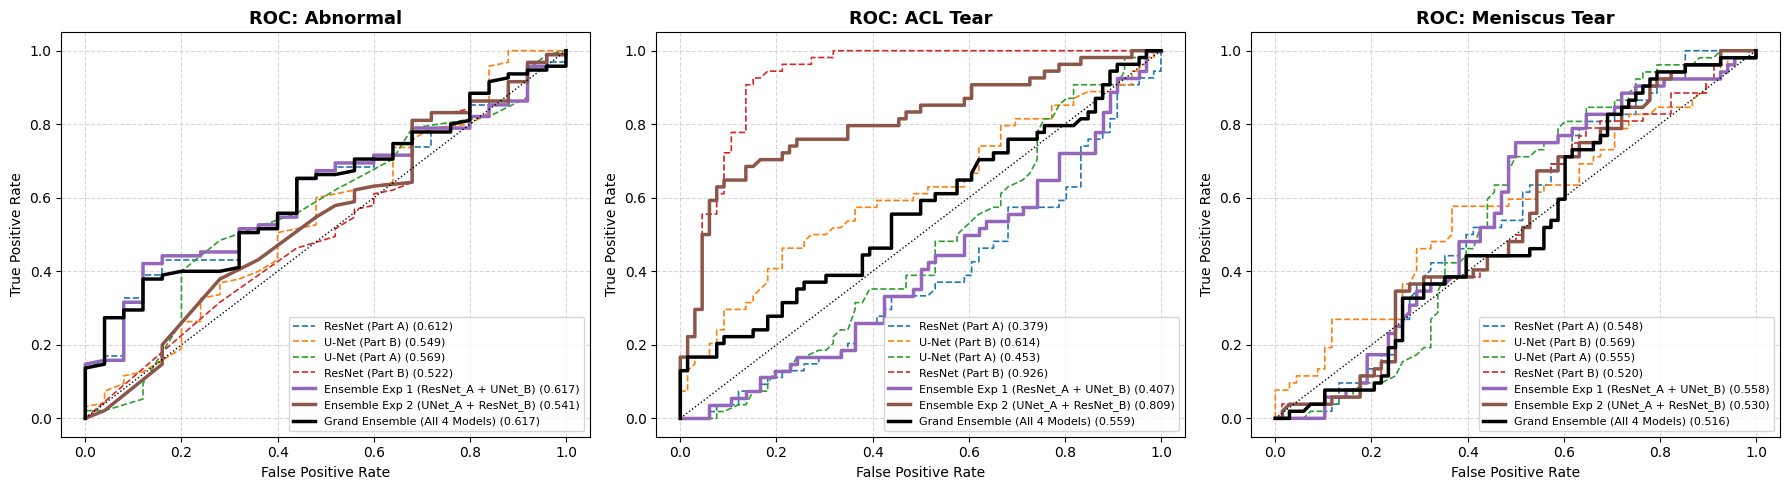

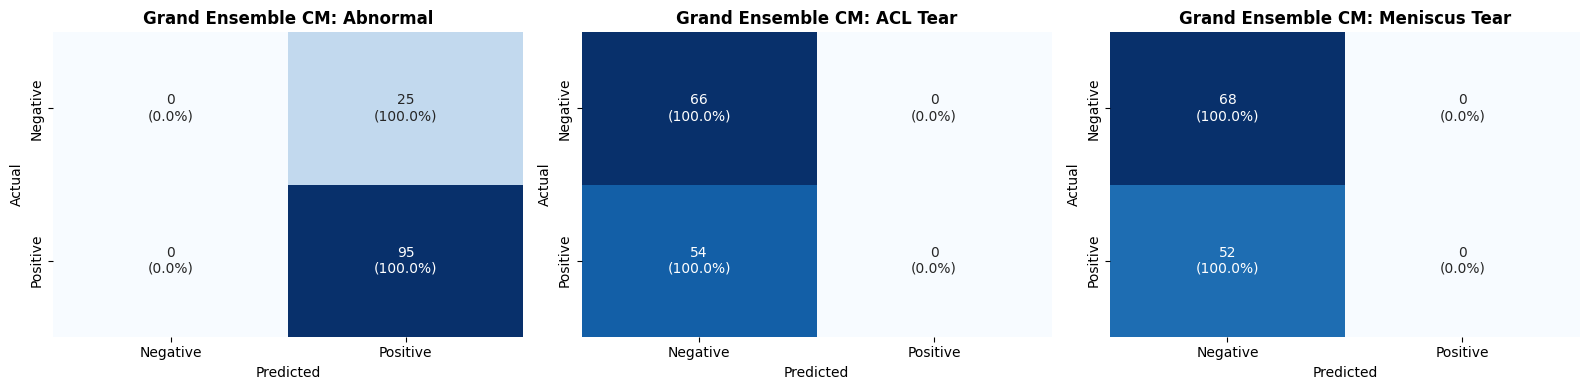

In [12]:
import seaborn as sns
from sklearn.metrics import roc_curve, confusion_matrix

conditions = ["Abnormal", "ACL Tear", "Meniscus Tear"]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#000000"]

# -------------------------------------------------------------
# PLOT 1: ROC Curves for all 3 conditions
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, task in enumerate(conditions):
    for (name, probs), col in zip(predictions_dict.items(), colors):
        fpr, tpr, _ = roc_curve(y_true[:, i], probs[:, i])
        auc = roc_auc_score(y_true[:, i], probs[:, i])
        is_ensemble = "Ensemble" in name
        axes[i].plot(fpr, tpr, label=f"{name} ({auc:.3f})", color=col,
                     linewidth=2.5 if is_ensemble else 1.2,
                     linestyle="-" if is_ensemble else "--")

    axes[i].plot([0, 1], [0, 1], 'k:', lw=1)
    axes[i].set_title(f"ROC: {task}", fontsize=13, fontweight='bold')
    axes[i].set_xlabel("False Positive Rate", fontsize=10)
    axes[i].set_ylabel("True Positive Rate", fontsize=10)
    axes[i].legend(loc="lower right", fontsize=8)
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# PLOT 2: Confusion Matrices for Grand Ensemble
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
grand_preds = (probs_ens_grand >= 0.5).astype(int)

for i, task in enumerate(conditions):
    cm = confusion_matrix(y_true[:, i], grand_preds[:, i], labels=[0, 1])
    cm_perc = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    lbls = np.array([
        [f"{cm[0,0]}\n({cm_perc[0,0]:.1f}%)", f"{cm[0,1]}\n({cm_perc[0,1]:.1f}%)"],
        [f"{cm[1,0]}\n({cm_perc[1,0]:.1f}%)", f"{cm[1,1]}\n({cm_perc[1,1]:.1f}%)"]
    ])
    sns.heatmap(cm, annot=lbls, fmt='', cmap="Blues", cbar=False, ax=axes[i],
                xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
    axes[i].set_title(f"Grand Ensemble CM: {task}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()